In [1]:
import boto3
import pandas as pd
from pathlib import PurePosixPath
from collections import Counter
from IPython.display import display

BUCKET_NAME = "amal-stitchingnet-data-903473565738-ap-southeast-2-an"

REGION = "ap-southeast-2"

DATA_PREFIX = "data/"

s3 = boto3.client(
    "s3",
    region_name=REGION
)

print("S3 connection established")

response = s3.head_bucket(
    Bucket=BUCKET_NAME
)

print("Bucket accessible:", response is not None)

S3 connection established
Bucket accessible: True


In [2]:
paginator = s3.get_paginator("list_objects_v2")

all_objects = []

for page in paginator.paginate(
    Bucket=BUCKET_NAME,
    Prefix=DATA_PREFIX
):

    objects = page.get("Contents", [])

    all_objects.extend(objects)

print("Total files found:", len(all_objects))

Total files found: 14565


In [3]:
records = []

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png",
    ".bmp", ".tif", ".tiff", ".webp"
}

for obj in all_objects:

    key = obj["Key"]

    if key.endswith("/"):
        continue

    path = PurePosixPath(key)

    relative_folders = path.parts[1:-1]

    records.append({

        "file_name": path.name,

        "s3_key": key,

        "extension": path.suffix.lower(),

        "file_size_kb": obj["Size"] / 1024,

        "last_modified": obj["LastModified"],

        "folder_1": (
            relative_folders[0]
            if len(relative_folders) > 0
            else None
        ),

        "folder_2": (
            relative_folders[1]
            if len(relative_folders) > 1
            else None
        ),

        "is_image": (
            path.suffix.lower() in IMAGE_EXTENSIONS
        )
    })

inventory_df = pd.DataFrame(records)

print("Inventory created")

display(inventory_df.head(10))

Inventory created


,file_name,s3_key,extension,file_size_kb,last_modified,folder_1,folder_2,is_image
0,A_00_001.jpg,data/A. Cotton-Poly/0. Normal/A_00_001.jpg,.jpg,64.271484,2026-11-02 23:09:59+00:00,A. Cotton-Poly,0. Normal,True
1,A_00_002.jpg,data/A. Cotton-Poly/0. Normal/A_00_002.jpg,.jpg,62.459961,2026-11-02 23:10:01+00:00,A. Cotton-Poly,0. Normal,True
2,A_00_003.jpg,data/A. Cotton-Poly/0. Normal/A_00_003.jpg,.jpg,65.544922,2026-11-02 23:10:02+00:00,A. Cotton-Poly,0. Normal,True
3,A_00_004.jpg,data/A. Cotton-Poly/0. Normal/A_00_004.jpg,.jpg,65.865234,2026-11-02 23:10:04+00:00,A. Cotton-Poly,0. Normal,True
4,A_00_005.jpg,data/A. Cotton-Poly/0. Normal/A_00_005.jpg,.jpg,65.416992,2026-11-02 23:10:05+00:00,A. Cotton-Poly,0. Normal,True
5,A_00_006.jpg,data/A. Cotton-Poly/0. Normal/A_00_006.jpg,.jpg,65.876953,2026-11-02 23:10:06+00:00,A. Cotton-Poly,0. Normal,True
6,A_00_007.jpg,data/A. Cotton-Poly/0. Normal/A_00_007.jpg,.jpg,63.198242,2026-11-02 23:10:08+00:00,A. Cotton-Poly,0. Normal,True
7,A_00_008.jpg,data/A. Cotton-Poly/0. Normal/A_00_008.jpg,.jpg,65.879883,2026-11-02 23:10:09+00:00,A. Cotton-Poly,0. Normal,True
8,A_00_009.jpg,data/A. Cotton-Poly/0. Normal/A_00_009.jpg,.jpg,66.357422,2026-11-02 23:10:10+00:00,A. Cotton-Poly,0. Normal,True
9,A_00_010.jpg,data/A. Cotton-Poly/0. Normal/A_00_010.jpg,.jpg,66.562500,2026-11-02 23:10:12+00:00,A. Cotton-Poly,0. Normal,True


In [4]:
print("Total objects:", len(inventory_df))

print(
    "Total images:",
    inventory_df["is_image"].sum()
)

print(
    "Non-image files:",
    (~inventory_df["is_image"]).sum()
)

print(
    "Total image storage (MB):",
    round(
        inventory_df.loc[
            inventory_df["is_image"],
            "file_size_kb"
        ].sum() / 1024,
        2
    )
)

Total objects: 14565
Total images: 14565
Non-image files: 0
Total image storage (MB): 914.16


In [4]:
extension_counts = (
    inventory_df["extension"]
    .value_counts()
)

display(extension_counts)

extension
.jpg    14565
Name: count, dtype: int64

In [5]:
image_df = inventory_df[
    inventory_df["is_image"]
].copy()

fabric_distribution = (
    image_df.groupby("folder_1")
    .size()
    .sort_values(ascending=False)
)

display(
    fabric_distribution.to_frame(
        name="image_count"
    )
)

,image_count
folder_1,
J. Oxford-Core,1416
A. Cotton-Poly,1394
H. Nylon-Core,1375
E. Polyester-Poly,1351
B. Linen-Poly,1333
K. Polyester (coated)-Core,1311
F. Satin-Core,1298
C. Denim-Poly,1278
D. Velveteen-Poly,1271


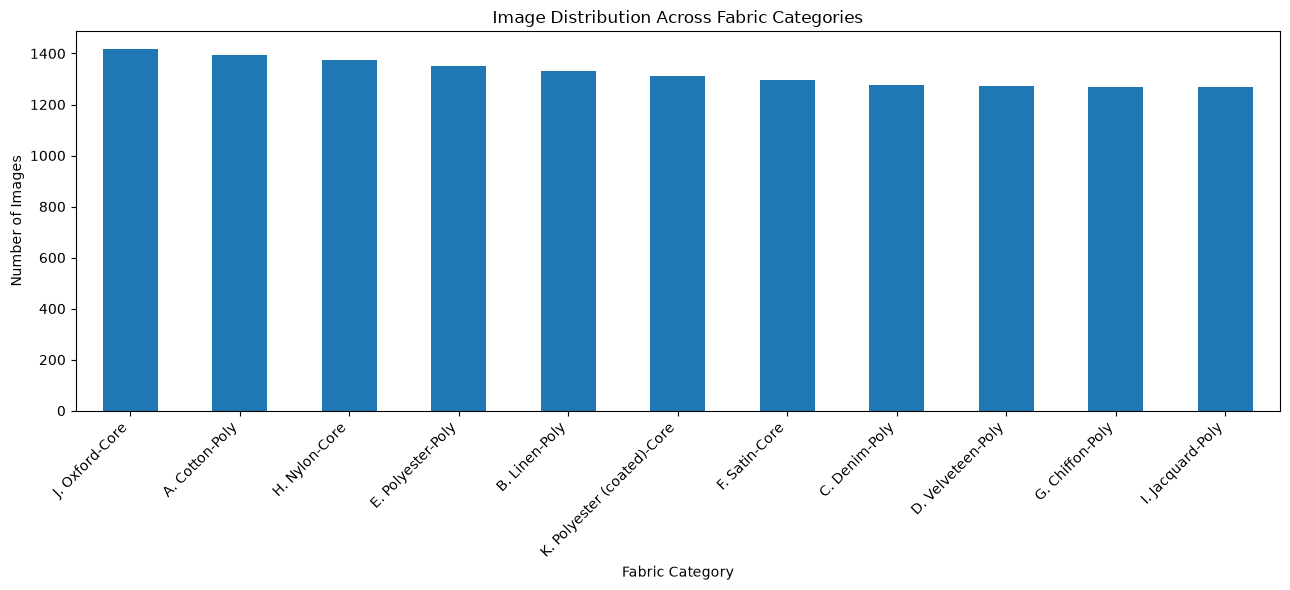

In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(13, 6))

fabric_distribution.plot(
    kind="bar"
)

plt.title("Image Distribution Across Fabric Categories")

plt.xlabel("Fabric Category")

plt.ylabel("Number of Images")

plt.xticks(rotation=45, ha="right")

plt.tight_layout()

plt.show()

In [7]:
folder_distribution = (
    image_df.groupby(
        ["folder_1", "folder_2"],
        dropna=False
    )
    .size()
    .reset_index(name="image_count")
    .sort_values("image_count", ascending=False)
)

display(folder_distribution.head(50))

,folder_1,folder_2,image_count
99,J. Oxford-Core,0. Normal,263
44,E. Polyester-Poly,0. Normal,250
55,F. Satin-Core,0. Normal,227
77,H. Nylon-Core,0. Normal,221
0,A. Cotton-Poly,0. Normal,220
11,B. Linen-Poly,0. Normal,220
66,G. Chiffon-Poly,0. Normal,217
110,K. Polyester (coated)-Core,0. Normal,215
33,D. Velveteen-Poly,0. Normal,203
22,C. Denim-Poly,0. Normal,200


In [8]:
for key in image_df["s3_key"].head(40):

    print(key)

data/A. Cotton-Poly/0. Normal/A_00_001.jpg
data/A. Cotton-Poly/0. Normal/A_00_002.jpg
data/A. Cotton-Poly/0. Normal/A_00_003.jpg
data/A. Cotton-Poly/0. Normal/A_00_004.jpg
data/A. Cotton-Poly/0. Normal/A_00_005.jpg
data/A. Cotton-Poly/0. Normal/A_00_006.jpg
data/A. Cotton-Poly/0. Normal/A_00_007.jpg
data/A. Cotton-Poly/0. Normal/A_00_008.jpg
data/A. Cotton-Poly/0. Normal/A_00_009.jpg
data/A. Cotton-Poly/0. Normal/A_00_010.jpg
data/A. Cotton-Poly/0. Normal/A_00_011.jpg
data/A. Cotton-Poly/0. Normal/A_00_012.jpg
data/A. Cotton-Poly/0. Normal/A_00_013.jpg
data/A. Cotton-Poly/0. Normal/A_00_014.jpg
data/A. Cotton-Poly/0. Normal/A_00_015.jpg
data/A. Cotton-Poly/0. Normal/A_00_016.jpg
data/A. Cotton-Poly/0. Normal/A_00_017.jpg
data/A. Cotton-Poly/0. Normal/A_00_018.jpg
data/A. Cotton-Poly/0. Normal/A_00_019.jpg
data/A. Cotton-Poly/0. Normal/A_00_020.jpg
data/A. Cotton-Poly/0. Normal/A_00_021.jpg
data/A. Cotton-Poly/0. Normal/A_00_022.jpg
data/A. Cotton-Poly/0. Normal/A_00_023.jpg
data/A. Cot

In [9]:
from pathlib import Path

Path("reports/eda").mkdir(
    parents=True,
    exist_ok=True
)

local_report = "reports/eda/01_s3_inventory.csv"

inventory_df.to_csv(
    local_report,
    index=False
)

s3.upload_file(
    local_report,
    BUCKET_NAME,
    "eda/01_s3_inventory.csv"
)

print("Inventory report uploaded successfully")

Inventory report uploaded successfully


In [10]:
# Count images in each stitching class

class_distribution = (
    image_df.groupby("folder_2")
    .size()
    .reset_index(name="image_count")
)

# Extract numeric class identifier
class_distribution["class_id"] = (
    class_distribution["folder_2"]
    .str.extract(r"^(\d+)")
    .astype(int)
)

class_distribution = (
    class_distribution
    .sort_values("class_id")
    .reset_index(drop=True)
)

display(class_distribution)

,folder_2,image_count,class_id
0,0. Normal,2436,0
1,1. Skipped stitch,1239,1
2,2. Broken stitch,1201,2
3,3. Pinched fabric,1192,3
4,4. Crooked seam,1230,4
5,5. Thread sagging,1173,5
6,6. Puckering,1240,6
7,7. Stain and damage,1162,7
8,8. Needle mark,1232,8
9,9. Bobbin thread pulling up,1257,9


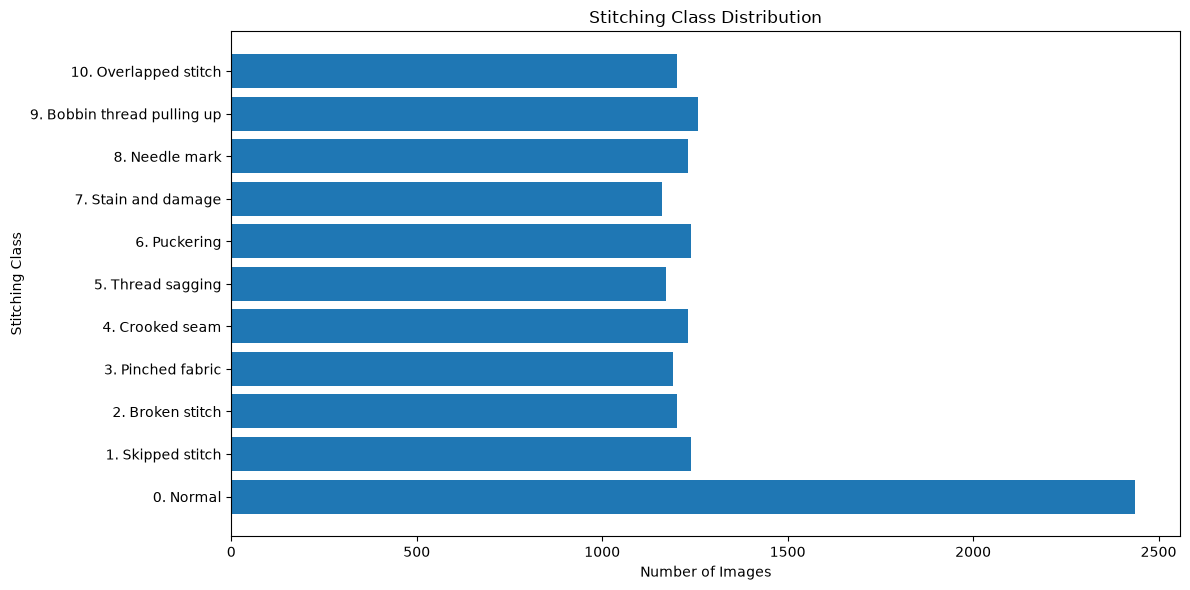

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.barh(
    class_distribution["folder_2"],
    class_distribution["image_count"]
)

plt.title("Stitching Class Distribution")

plt.xlabel("Number of Images")

plt.ylabel("Stitching Class")

plt.tight_layout()

plt.show()

In [12]:
counts = class_distribution["image_count"]

print("Largest class:", counts.max())
print("Smallest class:", counts.min())

print(
    "Imbalance ratio:",
    round(counts.max() / counts.min(), 2)
)

print(
    "Total images:",
    counts.sum()
)

Largest class: 2436
Smallest class: 1162
Imbalance ratio: 2.1
Total images: 14565


In [13]:
fabric_class_table = pd.crosstab(
    image_df["folder_1"],
    image_df["folder_2"]
)

display(fabric_class_table)

folder_2,0. Normal,1. Skipped stitch,10. Overlapped stitch,2. Broken stitch,3. Pinched fabric,4. Crooked seam,5. Thread sagging,6. Puckering,7. Stain and damage,8. Needle mark,9. Bobbin thread pulling up
folder_1,,,,,,,,,,,
A. Cotton-Poly,220,144,120,112,108,118,108,104,108,108,144
B. Linen-Poly,220,103,108,117,104,130,101,112,103,130,105
C. Denim-Poly,200,106,101,107,106,117,108,102,100,115,116
D. Velveteen-Poly,203,104,102,102,104,100,100,112,103,122,119
E. Polyester-Poly,250,108,120,102,105,107,112,121,102,106,118
F. Satin-Core,227,108,108,108,108,108,102,106,106,109,108
G. Chiffon-Poly,217,102,106,103,102,101,105,102,108,112,112
H. Nylon-Core,221,120,110,120,130,120,120,110,112,110,102
I. Jacquard-Poly,200,110,104,103,108,105,100,113,106,109,110


In [14]:
import re

name_parts = image_df["file_name"].str.extract(
    r"^([A-Z])_(\d{2})_(\d+)\.([A-Za-z0-9]+)$"
)

validation_df = pd.DataFrame({

    "filename_fabric": name_parts[0],

    "folder_fabric": image_df["folder_1"].str.extract(
        r"^([A-Z])\."
    )[0],

    "filename_class": pd.to_numeric(
        name_parts[1],
        errors="coerce"
    ),

    "folder_class": pd.to_numeric(
        image_df["folder_2"].str.extract(
            r"^(\d+)"
        )[0],
        errors="coerce"
    )
})

print(
    "Invalid filename patterns:",
    name_parts.isna().any(axis=1).sum()
)

print(
    "Fabric code mismatches:",
    (validation_df["filename_fabric"] !=
     validation_df["folder_fabric"]).sum()
)

print(
    "Class code mismatches:",
    (validation_df["filename_class"] !=
     validation_df["folder_class"]).sum()
)

Invalid filename patterns: 0
Fabric code mismatches: 0
Class code mismatches: 0


In [15]:
# Reorder columns by numerical class ID
class_order = (
    class_distribution
    .sort_values("class_id")["folder_2"]
    .tolist()
)

fabric_class_table = fabric_class_table.reindex(
    columns=class_order
)

# Convert counts into percentages within each fabric
fabric_class_percentages = (
    fabric_class_table
    .div(fabric_class_table.sum(axis=1), axis=0)
    * 100
)

display(fabric_class_percentages.round(1))

folder_2,0. Normal,1. Skipped stitch,2. Broken stitch,3. Pinched fabric,4. Crooked seam,5. Thread sagging,6. Puckering,7. Stain and damage,8. Needle mark,9. Bobbin thread pulling up,10. Overlapped stitch
folder_1,,,,,,,,,,,
A. Cotton-Poly,15.8,10.3,8.0,7.7,8.5,7.7,7.5,7.7,7.7,10.3,8.6
B. Linen-Poly,16.5,7.7,8.8,7.8,9.8,7.6,8.4,7.7,9.8,7.9,8.1
C. Denim-Poly,15.6,8.3,8.4,8.3,9.2,8.5,8.0,7.8,9.0,9.1,7.9
D. Velveteen-Poly,16.0,8.2,8.0,8.2,7.9,7.9,8.8,8.1,9.6,9.4,8.0
E. Polyester-Poly,18.5,8.0,7.5,7.8,7.9,8.3,9.0,7.5,7.8,8.7,8.9
F. Satin-Core,17.5,8.3,8.3,8.3,8.3,7.9,8.2,8.2,8.4,8.3,8.3
G. Chiffon-Poly,17.1,8.0,8.1,8.0,8.0,8.3,8.0,8.5,8.8,8.8,8.3
H. Nylon-Core,16.1,8.7,8.7,9.5,8.7,8.7,8.0,8.1,8.0,7.4,8.0
I. Jacquard-Poly,15.8,8.7,8.1,8.5,8.3,7.9,8.9,8.4,8.6,8.7,8.2


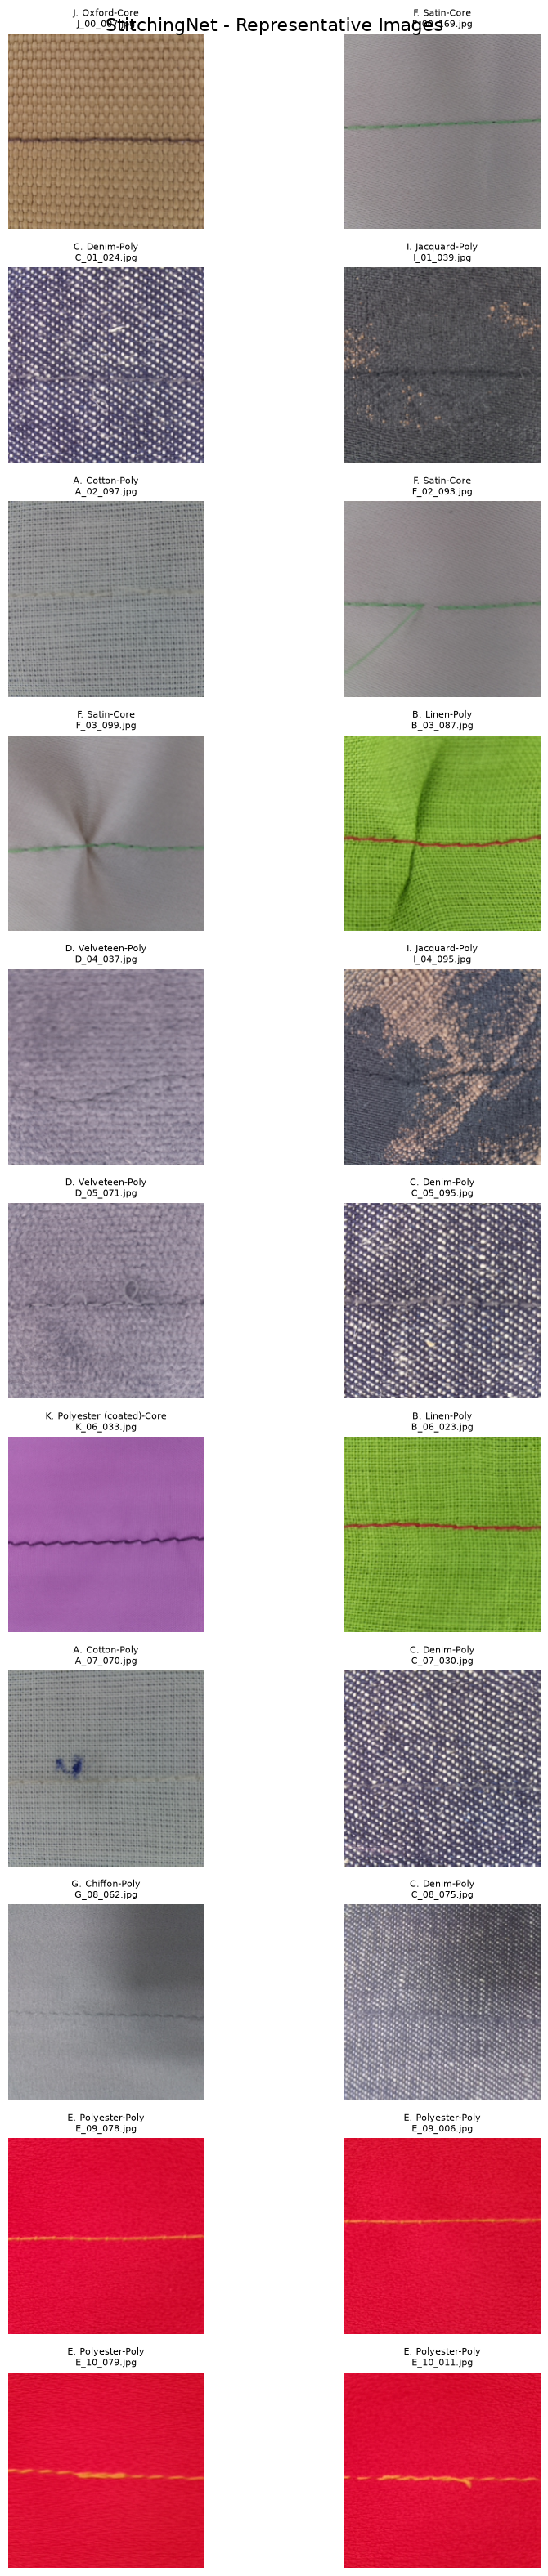

,fabric,class,filename,width,height,mode,format
0,J. Oxford-Core,0. Normal,J_00_007.jpg,224,224,RGB,JPEG
1,F. Satin-Core,0. Normal,F_00_169.jpg,224,224,RGB,JPEG
2,C. Denim-Poly,1. Skipped stitch,C_01_024.jpg,224,224,RGB,JPEG
3,I. Jacquard-Poly,1. Skipped stitch,I_01_039.jpg,224,224,RGB,JPEG
4,A. Cotton-Poly,2. Broken stitch,A_02_097.jpg,224,224,RGB,JPEG
5,F. Satin-Core,2. Broken stitch,F_02_093.jpg,224,224,RGB,JPEG
6,F. Satin-Core,3. Pinched fabric,F_03_099.jpg,224,224,RGB,JPEG
7,B. Linen-Poly,3. Pinched fabric,B_03_087.jpg,224,224,RGB,JPEG
8,D. Velveteen-Poly,4. Crooked seam,D_04_037.jpg,224,224,RGB,JPEG
9,I. Jacquard-Poly,4. Crooked seam,I_04_095.jpg,224,224,RGB,JPEG


In [16]:
from io import BytesIO
from PIL import Image
import matplotlib.pyplot as plt
import pandas as pd

# Select 2 random images from every stitching class
sample_df = (
    image_df
    .groupby("folder_2", group_keys=False)
    .sample(n=2, random_state=42)
)

sample_records = []

fig, axes = plt.subplots(
    nrows=11,
    ncols=2,
    figsize=(10, 32)
)

for row_idx, class_name in enumerate(class_order):

    class_samples = (
        sample_df[
            sample_df["folder_2"] == class_name
        ]
        .reset_index(drop=True)
    )

    for col_idx in range(2):

        row = class_samples.iloc[col_idx]

        # Download one image from S3
        response = s3.get_object(
            Bucket=BUCKET_NAME,
            Key=row["s3_key"]
        )

        image_bytes = response["Body"].read()

        # Open and decode image
        with Image.open(
            BytesIO(image_bytes)
        ) as original:

            original.load()

            width, height = original.size
            mode = original.mode
            image_format = original.format

            image = original.convert("RGB")

        # Display image
        ax = axes[row_idx, col_idx]

        ax.imshow(image)

        ax.set_title(
            f"{row['folder_1']}\n{row['file_name']}",
            fontsize=8
        )

        ax.axis("off")

        sample_records.append({
            "fabric": row["folder_1"],
            "class": class_name,
            "filename": row["file_name"],
            "width": width,
            "height": height,
            "mode": mode,
            "format": image_format
        })

plt.suptitle(
    "StitchingNet - Representative Images",
    fontsize=16
)

plt.tight_layout()

plt.show()

sample_metadata = pd.DataFrame(sample_records)

display(sample_metadata)